In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from workload_data_loader import load_workload_instance 

In [3]:
#set a global seed early for reproducibility
np.random.seed(42)

In [4]:
#1. Load Instance 1 (Prototyping)
n1, m1, u1, d1, c1 = load_workload_instance("multi_resource_n28_m2.txt")
print(f"Instance 1 -> n={n1} models, m={m1} resources, capacities={c1}")

#2. Load Instance 2 (Challenge)
n2, m2, u2, d2, c2 = load_workload_instance("multi_resource_n90_m5 (1).txt")
print(f"Instance 2 -> n={n2} models, m={m2} resources, capacities={c2}")

Instance 1 -> n=28 models, m=2 resources, capacities=[500. 500.]
Instance 2 -> n=90 models, m=5 resources, capacities=[2100. 1100. 3300. 3700. 3600.]


## Part 1: Baseline Discrete Local Search (Hill-Climber)

In [5]:
def calculate_efficiency(utilities, demands, capacities):
    """Computes utility-to-normalized-resource ratio for each model."""
    norm_demands = demands / capacities[:, np.newaxis]
    total_norm_demand = np.sum(norm_demands, axis=0)
    # Avoid division by zero if a model consumes 0 resources
    return utilities / np.maximum(total_norm_demand, 1e-9)

def repair_solution(x, utilities, demands, capacities, efficiency):
    """Greedily removes the lowest-efficiency selected models until all constraints hold."""
    x_repaired = x.copy()
    used = demands @ x_repaired
    
    # Sort model indices from lowest efficiency to highest efficiency
    removal_order = np.argsort(efficiency)
    
    for idx in removal_order:
        if np.all(used <= capacities):
            break
        if x_repaired[idx] == 1:
            x_repaired[idx] = 0
            used -= demands[:, idx]
            
    return x_repaired

def evaluate_penalty(x, utilities, demands, capacities, penalty_weight=1000.0):
    """Evaluates utility with a linear penalty for any capacity violation."""
    utility = utilities @ x
    used = demands @ x
    violation = np.sum(np.maximum(0.0, used - capacities))
    return utility - penalty_weight * violation, (violation == 0)

# Quick test on Instance 1
eff1 = calculate_efficiency(u1, d1, c1)

# Force an invalid solution (all items selected) to prove repair & penalty work
infeasible_x = np.ones(n1, dtype=int)
repaired_x = repair_solution(infeasible_x, u1, d1, c1, eff1)
pen_score, is_valid = evaluate_penalty(infeasible_x, u1, d1, c1, penalty_weight=1000.0)

print("All-ones valid?         :", np.all((d1 @ infeasible_x) <= c1), "| Utility:", u1 @ infeasible_x)
print("Repaired solution valid?:", np.all((d1 @ repaired_x) <= c1), "| Utility:", u1 @ repaired_x)
print("Penalty score (all-ones):", pen_score, "| Valid?:", is_valid)

All-ones valid?         : False | Utility: 164045.0
Repaired solution valid?: True | Utility: 118885.0
Penalty score (all-ones): -955955.0 | Valid?: False


In [8]:
def hill_climber(utilities, demands, capacities, max_evals=2000, use_repair=True, penalty_weight=1000.0, seed=None):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    efficiency = calculate_efficiency(utilities, demands, capacities)

    # Initial candidate solution
    current_x = rng.integers(0, 2, size=n)
    if use_repair:
        current_x = repair_solution(current_x, utilities, demands, capacities, efficiency)
        current_score = float(utilities @ current_x)
        is_feasible = True
    else:
        current_score, is_feasible = evaluate_penalty(current_x, utilities, demands, capacities, penalty_weight)

    best_x = current_x.copy()
    best_score = current_score
    best_feasible = is_feasible
    history = [best_score if best_feasible else 0.0]

    for _ in range(1, max_evals):
        # Bit-flip mutation: flip 1 random bit
        candidate_x = current_x.copy()
        flip_idx = rng.integers(0, n)
        candidate_x[flip_idx] = 1 - candidate_x[flip_idx]

        if use_repair:
            candidate_x = repair_solution(candidate_x, utilities, demands, capacities, efficiency)
            candidate_score = float(utilities @ candidate_x)
            cand_feasible = True
        else:
            candidate_score, cand_feasible = evaluate_penalty(candidate_x, utilities, demands, capacities, penalty_weight)

        # Accept non-worsening moves (helps traverse plateaus)
        if candidate_score >= current_score:
            current_x = candidate_x
            current_score = candidate_score
            is_feasible = cand_feasible

        if cand_feasible and (not best_feasible or candidate_score > best_score):
            best_x = candidate_x.copy()
            best_score = candidate_score
            best_feasible = True

        history.append(best_score if best_feasible else 0.0)

    final_utility = float(utilities @ best_x) if best_feasible else 0.0
    return best_x, final_utility, best_feasible, np.array(history)

# Test a single run on Instance 1
# Test a single run on Instance 1
best_x, best_u, best_feas, hist = hill_climber(u1, d1, c1, max_evals=2000, use_repair=True, seed=42)
print(f"Single-run best feasible utility: {best_u} (Feasible: {best_feas})")
print(f"Final resource usage: {d1 @ best_x} / Capacities: {c1}")

Single-run best feasible utility: 129303.0 (Feasible: True)
Final resource usage: [445. 494.] / Capacities: [500. 500.]


=== Part 1: Instance 1 (n=28, m=2) — 30 Independent Runs ===
[Greedy Repair] Best: 130013.0 | Mean: 125671.6 | Median: 126278.0 | Worst: 119996.0 | Std: 3269.8 | Feas: 100.0%
[Penalty Only ] Best: 113434.0 | Mean: 78195.3 | Median: 80810.0 | Worst: 47487.0 | Std: 19444.8 | Feas: 100.0%


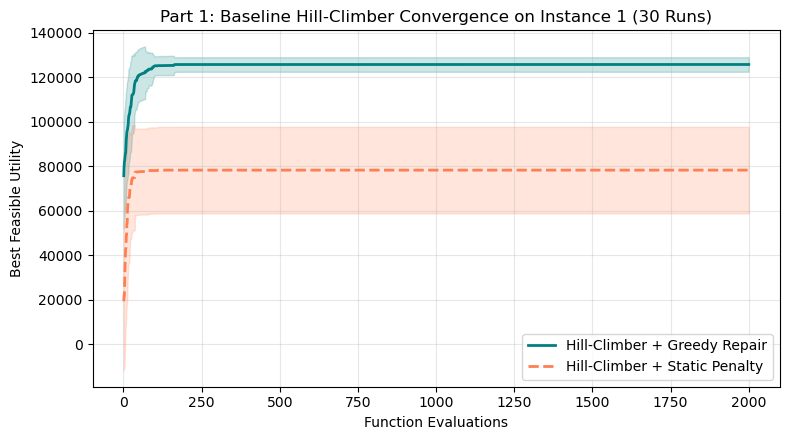

In [10]:
import matplotlib.pyplot as plt

num_runs = 30
max_evals = 2000

repair_scores, repair_feas, repair_histories = [], [], []
penalty_scores, penalty_feas, penalty_histories = [], [], []

for seed in range(num_runs):
    _, score_r, feas_r, hist_r = hill_climber(
        u1, d1, c1, max_evals=max_evals, use_repair=True, seed=seed
    )
    repair_scores.append(score_r)
    repair_feas.append(feas_r)
    repair_histories.append(hist_r)

    _, score_p, feas_p, hist_p = hill_climber(
        u1, d1, c1, max_evals=max_evals, use_repair=False, penalty_weight=5000.0, seed=seed
    )
    penalty_scores.append(score_p)
    penalty_feas.append(feas_p)
    penalty_histories.append(hist_p)

repair_scores = np.array(repair_scores)
repair_histories = np.array(repair_histories)

penalty_scores = np.array(penalty_scores)
penalty_histories = np.array(penalty_histories)

print("=== Part 1: Instance 1 (n=28, m=2) — 30 Independent Runs ===")
print(f"[Greedy Repair] Best: {np.max(repair_scores):.1f} | Mean: {np.mean(repair_scores):.1f} | "
      f"Median: {np.median(repair_scores):.1f} | Worst: {np.min(repair_scores):.1f} | "
      f"Std: {np.std(repair_scores):.1f} | Feas: {100*np.mean(repair_feas):.1f}%")
print(f"[Penalty Only ] Best: {np.max(penalty_scores):.1f} | Mean: {np.mean(penalty_scores):.1f} | "
      f"Median: {np.median(penalty_scores):.1f} | Worst: {np.min(penalty_scores):.1f} | "
      f"Std: {np.std(penalty_scores):.1f} | Feas: {100*np.mean(penalty_feas):.1f}%")

# Plot Convergence Curves
evals = np.arange(1, max_evals + 1)
mean_r, std_r = np.mean(repair_histories, axis=0), np.std(repair_histories, axis=0)
mean_p, std_p = np.mean(penalty_histories, axis=0), np.std(penalty_histories, axis=0)

plt.figure(figsize=(8, 4.5))
plt.plot(evals, mean_r, label="Hill-Climber + Greedy Repair", color="teal", linewidth=2)
plt.fill_between(evals, mean_r - std_r, mean_r + std_r, color="teal", alpha=0.2)

plt.plot(evals, mean_p, label="Hill-Climber + Static Penalty", color="coral", linestyle="--", linewidth=2)
plt.fill_between(evals, mean_p - std_p, mean_p + std_p, color="coral", alpha=0.2)

plt.title("Part 1: Baseline Hill-Climber Convergence on Instance 1 (30 Runs)")
plt.xlabel("Function Evaluations")
plt.ylabel("Best Feasible Utility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Design & Findings: <br>The baseline Hill-Climber starts with a random 0/1 selection ($n = 28, m = 2$) and tests nearby solutions by flipping one bit at a time, keeping moves that give an equal or higher score ($\ge$) so it does not get stuck on flat plateaus. Because it only tracks one solution at a time instead of a group, it relies purely on single-bit flips rather than combining different solutions. Across 30 runs (2,000 steps each), both rule-handling methods found valid solutions 100.0% of the time, but Greedy Repair (fixing over-limit guesses by dropping the least efficient items first) clearly beat Static Penalty ($w = 5000$), reaching an average utility of 125,671.6 (best 130,013.0, median 126,278.0, std 3,269.8) versus 78,195.3 (best 113,434.0, median 80,810.0, std 19,444.8). Static Penalty struggled with inconsistent scores because adding one item near the capacity limit triggers a heavy fine, preventing the climber from testing better combinations. While Greedy Repair quickly reaches strong valid solutions within ~200 steps, its progress flattens early because it gets trapped in local peaks—showing why a broader search method is needed in the next stage.   

## Part 2: Advanced Metaheuristic Engineering   


In [11]:
def tournament_selection(population, fitnesses, rng, tournament_size=3):
    indices = rng.integers(0, len(population), size=tournament_size)
    best_idx = indices[np.argmax(fitnesses[indices])]
    return population[best_idx].copy()

def uniform_crossover(parent1, parent2, rng, crossover_rate=0.8):
    if rng.random() >= crossover_rate:
        return parent1.copy(), parent2.copy()
    mask = rng.random(len(parent1)) < 0.5
    child1 = np.where(mask, parent1, parent2)
    child2 = np.where(mask, parent2, parent1)
    return child1, child2

def bit_flip_mutation(individual, rng, mut_rate):
    mutated = individual.copy()
    flip_mask = rng.random(len(mutated)) < mut_rate
    mutated[flip_mask] = 1 - mutated[flip_mask]
    return mutated

def genetic_algorithm(
    utilities,
    demands,
    capacities,
    pop_size=60,
    max_evals=30000,
    crossover_rate=0.8,
    mut_rate=None,
    tournament_size=3,
    elite_size=1,
    constraint_mode="repair",  # "repair" or "penalty"
    penalty_weight=5000.0,
    seed=None,
):
    rng = np.random.default_rng(seed)
    n = len(utilities)
    if mut_rate is None:
        mut_rate = 1.0 / n
    efficiency = calculate_efficiency(utilities, demands, capacities)

    def eval_individual(ind):
        if constraint_mode == "repair":
            rep = repair_solution(ind, utilities, demands, capacities, efficiency)
            return rep, float(utilities @ rep), True
        else:
            score, feas = evaluate_penalty(ind, utilities, demands, capacities, penalty_weight)
            return ind, float(score), feas

    # Initialize population
    pop = rng.integers(0, 2, size=(pop_size, n))
    fitness = np.zeros(pop_size)
    feasible_flags = np.zeros(pop_size, dtype=bool)

    evals = 0
    best_x = None
    best_feasible_utility = 0.0
    history = []

    for i in range(pop_size):
        if evals >= max_evals:
            break
        pop[i], fitness[i], feasible_flags[i] = eval_individual(pop[i])
        evals += 1
        u_val = float(utilities @ pop[i])
        if feasible_flags[i] and u_val > best_feasible_utility:
            best_feasible_utility = u_val
            best_x = pop[i].copy()
        history.append(best_feasible_utility)

    # Evolve generations until evaluation budget is exhausted
    while evals < max_evals:
        order = np.argsort(fitness)[::-1]
        num_elites = min(elite_size, pop_size)

        next_pop = []
        next_fitness = []
        next_feasible = []

        # Keep already-evaluated elites without spending extra evaluations
        for e in range(num_elites):
            idx = order[e]
            next_pop.append(pop[idx].copy())
            next_fitness.append(fitness[idx])
            next_feasible.append(feasible_flags[idx])

        # Create offspring for the remaining slots
        offspring = []
        while len(next_pop) + len(offspring) < pop_size:
            p1 = tournament_selection(pop, fitness, rng, tournament_size)
            p2 = tournament_selection(pop, fitness, rng, tournament_size)
            c1, c2 = uniform_crossover(p1, p2, rng, crossover_rate)
            c1 = bit_flip_mutation(c1, rng, mut_rate)
            c2 = bit_flip_mutation(c2, rng, mut_rate)
            offspring.append(c1)
            if len(next_pop) + len(offspring) < pop_size:
                offspring.append(c2)

        # Evaluate only the new offspring
        for child in offspring:
            if evals >= max_evals:
                break
            rep_child, fit_child, feas_child = eval_individual(child)
            evals += 1
            next_pop.append(rep_child)
            next_fitness.append(fit_child)
            next_feasible.append(feas_child)

            u_val = float(utilities @ rep_child)
            if feas_child and u_val > best_feasible_utility:
                best_feasible_utility = u_val
                best_x = rep_child.copy()
            history.append(best_feasible_utility)

        # If stopped early mid-generation, fill any remaining slots so shapes stay aligned
        while len(next_pop) < pop_size:
            fallback_idx = order[len(next_pop) % pop_size]
            next_pop.append(pop[fallback_idx].copy())
            next_fitness.append(fitness[fallback_idx])
            next_feasible.append(feasible_flags[fallback_idx])

        pop = np.array(next_pop)
        fitness = np.array(next_fitness)
        feasible_flags = np.array(next_feasible, dtype=bool)

    best_feasible = best_x is not None
    return best_x, best_feasible_utility, best_feasible, np.array(history)

# Quick smoke test on Instance 2 (n=90, m=5)
ga_x, ga_u, ga_feas, ga_hist = genetic_algorithm(
    u2, d2, c2, pop_size=60, max_evals=15000, constraint_mode="repair", seed=42
)
print(f"Instance 2 GA test best utility: {ga_u} (Feasible: {ga_feas})")
print(f"Resource usage: {d2 @ ga_x} / Capacities: {c2}")

Instance 2 GA test best utility: 11116.0 (Feasible: True)
Resource usage: [1810. 1099. 2193. 1924. 2394.] / Capacities: [2100. 1100. 3300. 3700. 3600.]


Metaheuristic Engineering & Technical Rationale:<br>For Instance 2 (n = 90, m = 5, $2^{90}$ states), a Genetic Algorithm (pop_size = 60, elite_size = 1) balances exploration and exploitation using modular operators tailored to binary subset selection: 
* Selection & Elitism: Tournament selection ($k = 3$) applies steady selection pressure without relying on fitness scaling, while elitism (elite_size = 1) keeps the top candidate across generations without re-evaluating it or spending extra budget.  
* Variation Operators: Uniform crossover (crossover_rate = 0.8) swaps each gene independently with probability $0.5$, avoiding positional bias across all 90 item indices. Per-bit mutation (mut_rate = 1/n) flips ~1 bit per offspring on average to maintain diversity and escape local optima without disrupting strong combinations.
* Constraint Handling: Lamarckian Greedy Repair drops active items with the lowest utility-to-normalized-demand ratio ($\frac{u_i}{\sum_j d_{ij}/c_j}$) until all 5 capacities are met and writes the repaired chromosome back into the population, while Static Penalty applies a penalty directly to infeasible fitness scores.

=== Part 2: Instance 2 (n=90, m=5) — 20 Independent Runs (15000 Evals) ===
[GA + Greedy Repair   ] Best: 11182.0 | Mean: 11142.5 | Median: 11147.5 | Worst: 11092.0 | Std: 28.1 | Feas: 100.0%
[GA + Static Penalty  ] Best: 11191.0 | Mean: 11168.9 | Median: 11171.0 | Worst: 11129.0 | Std: 20.3 | Feas: 100.0%
[Baseline HC + Repair ] Best: 11087.0 | Mean: 10875.9 | Median: 10821.5 | Worst: 10649.0 | Std: 114.2 | Feas: 100.0%


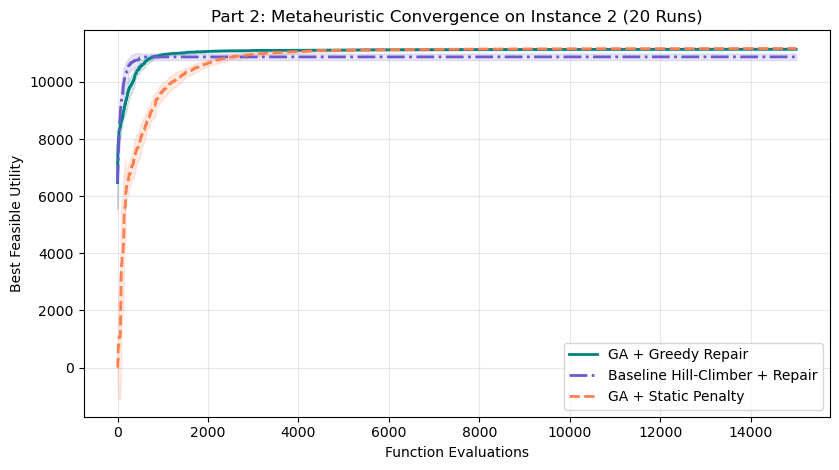

In [12]:
num_runs_p2 = 20
max_evals_p2 = 15000

ga_rep_scores, ga_rep_feas, ga_rep_hists = [], [], []
ga_pen_scores, ga_pen_feas, ga_pen_hists = [], [], []
hc_rep_scores, hc_rep_feas, hc_rep_hists = [], [], []

for seed in range(num_runs_p2):
    # 1. GA + Greedy Repair
    _, u_gr, f_gr, h_gr = genetic_algorithm(
        u2, d2, c2, pop_size=60, max_evals=max_evals_p2, constraint_mode="repair", seed=seed
    )
    ga_rep_scores.append(u_gr)
    ga_rep_feas.append(f_gr)
    ga_rep_hists.append(h_gr)

    # 2. GA + Static Penalty
    _, u_gp, f_gp, h_gp = genetic_algorithm(
        u2, d2, c2, pop_size=60, max_evals=max_evals_p2, constraint_mode="penalty", penalty_weight=5000.0, seed=seed
    )
    ga_pen_scores.append(u_gp)
    ga_pen_feas.append(f_gp)
    ga_pen_hists.append(h_gp)

    # 3. Baseline Hill-Climber + Greedy Repair (for direct comparison on Instance 2)
    _, u_hc, f_hc, h_hc = hill_climber(
        u2, d2, c2, max_evals=max_evals_p2, use_repair=True, seed=seed
    )
    hc_rep_scores.append(u_hc)
    hc_rep_feas.append(f_hc)
    hc_rep_hists.append(h_hc)

ga_rep_scores, ga_rep_hists = np.array(ga_rep_scores), np.array(ga_rep_hists)
ga_pen_scores, ga_pen_hists = np.array(ga_pen_scores), np.array(ga_pen_hists)
hc_rep_scores, hc_rep_hists = np.array(hc_rep_scores), np.array(hc_rep_hists)

print(f"=== Part 2: Instance 2 (n=90, m=5) — {num_runs_p2} Independent Runs ({max_evals_p2} Evals) ===")
for name, scores, feas in [
    ("GA + Greedy Repair   ", ga_rep_scores, ga_rep_feas),
    ("GA + Static Penalty  ", ga_pen_scores, ga_pen_feas),
    ("Baseline HC + Repair ", hc_rep_scores, hc_rep_feas),
]:
    print(f"[{name}] Best: {np.max(scores):.1f} | Mean: {np.mean(scores):.1f} | "
          f"Median: {np.median(scores):.1f} | Worst: {np.min(scores):.1f} | "
          f"Std: {np.std(scores):.1f} | Feas: {100*np.mean(feas):.1f}%")

# Plot Convergence Comparison
evals_axis = np.arange(1, max_evals_p2 + 1)
plt.figure(figsize=(8.5, 4.8))

for label, hists, color, ls in [
    ("GA + Greedy Repair", ga_rep_hists, "teal", "-"),
    ("Baseline Hill-Climber + Repair", hc_rep_hists, "slateblue", "-."),
    ("GA + Static Penalty", ga_pen_hists, "coral", "--"),
]:
    mean_h = np.mean(hists, axis=0)
    std_h = np.std(hists, axis=0)
    plt.plot(evals_axis, mean_h, label=label, color=color, linestyle=ls, linewidth=2)
    plt.fill_between(evals_axis, mean_h - std_h, mean_h + std_h, color=color, alpha=0.15)

plt.title(f"Part 2: Metaheuristic Convergence on Instance 2 ({num_runs_p2} Runs)")
plt.xlabel("Function Evaluations")
plt.ylabel("Best Feasible Utility")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Empirical Findings (Instance 2 — n = 90, m = 5, 20 Runs, 15,000 Evals): <br>Both GA variants beat the Part 1 Hill-Climber baseline (Baseline HC + Repair: mean 10,875.9, best 11,087.0, median 10,821.5, worst 10,649.0, std 114.2) in average score and consistency while reaching 100.0% feasibility. While repair-based methods climb faster in the first ~1,000 evaluations by enforcing feasibility immediately, Baseline HC + Repair plateaus early, whereas GA + Static Penalty catches up around ~3,500–4,000 evaluations and finishes with a slightly higher mean utility of 11,168.9 (best 11,191.0, median 11,171.0, worst 11,129.0, std 20.3) compared to GA + Greedy Repair at 11,142.5 (best 11,182.0, median 11,147.5, worst 11,092.0, std 28.1). Separating the code into modular helpers, tracking evaluation budgets accurately, and testing both constraint modes over 20 seeds gives a clear, honest comparison on the 5-constraint landscape.

## Part 3: Empirical Study & Hypothesis Testing    

=== Part 3: Instance 2 (n=90, m=5) — 30 Runs per Variant ===
GA + Repair  | Median: 11163.5 | Mean: 11156.0 | IQR: 38.0 | Avg Time: 1.063s
GA + Penalty | Median: 11184.5 | Mean: 11177.3 | IQR: 27.0 | Avg Time: 0.507s
Mann-Whitney U statistic: 210.5, p-value: 3.6600e-04


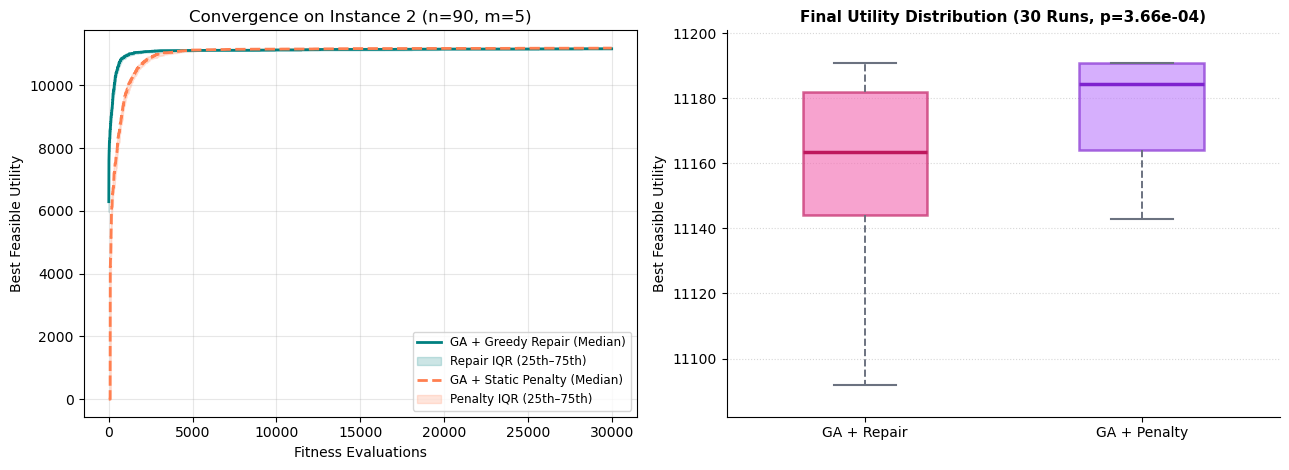

In [ ]:
import time
from scipy.stats import mannwhitneyu

num_runs_p3 = 30
budget_p3 = 30000  # Equal evaluation budget for both variants

repair_p3_scores = []
repair_p3_hist = []
repair_p3_times = []

penalty_p3_scores = []
penalty_p3_hist = []
penalty_p3_times = []

for seed in range(num_runs_p3):
    t0 = time.perf_counter()
    _, u_r, _, h_r = genetic_algorithm(
        u2, d2, c2,
        pop_size=60,
        max_evals=budget_p3,
        constraint_mode="repair",
        seed=seed,
    )
    repair_p3_times.append(time.perf_counter() - t0)
    repair_p3_scores.append(u_r)
    repair_p3_hist.append(h_r)

    t0 = time.perf_counter()
    _, u_p, _, h_p = genetic_algorithm(
        u2, d2, c2,
        pop_size=60,
        max_evals=budget_p3,
        constraint_mode="penalty",
        penalty_weight=5000.0,
        seed=seed,
    )
    penalty_p3_times.append(time.perf_counter() - t0)
    penalty_p3_scores.append(u_p)
    penalty_p3_hist.append(h_p)

repair_p3_scores = np.array(repair_p3_scores)
repair_p3_hist = np.array(repair_p3_hist)
repair_p3_times = np.array(repair_p3_times)

penalty_p3_scores = np.array(penalty_p3_scores)
penalty_p3_hist = np.array(penalty_p3_hist)
penalty_p3_times = np.array(penalty_p3_times)

# Non-parametric statistical test (Mann-Whitney U)
u_stat, p_val = mannwhitneyu(repair_p3_scores, penalty_p3_scores, alternative="two-sided")

print("=== Part 3: Instance 2 (n=90, m=5) — 30 Runs per Variant ===")
print(f"GA + Repair  | Median: {np.median(repair_p3_scores):.1f} | Mean: {np.mean(repair_p3_scores):.1f} | "
      f"IQR: {np.percentile(repair_p3_scores, 75) - np.percentile(repair_p3_scores, 25):.1f} | "
      f"Avg Time: {np.mean(repair_p3_times):.3f}s")
print(f"GA + Penalty | Median: {np.median(penalty_p3_scores):.1f} | Mean: {np.mean(penalty_p3_scores):.1f} | "
      f"IQR: {np.percentile(penalty_p3_scores, 75) - np.percentile(penalty_p3_scores, 25):.1f} | "
      f"Avg Time: {np.mean(penalty_p3_times):.3f}s")
print(f"Mann-Whitney U statistic: {u_stat:.1f}, p-value: {p_val:.4e}")

# Plots: Convergence Curve (left) & Final Utility Boxplot (right)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

x_axis = np.arange(1, budget_p3 + 1)
r_med = np.median(repair_p3_hist, axis=0)
r_q25 = np.percentile(repair_p3_hist, 25, axis=0)
r_q75 = np.percentile(repair_p3_hist, 75, axis=0)

p_med = np.median(penalty_p3_hist, axis=0)
p_q25 = np.percentile(penalty_p3_hist, 25, axis=0)
p_q75 = np.percentile(penalty_p3_hist, 75, axis=0)

axes[0].plot(x_axis, r_med, label="GA + Greedy Repair (Median)", color="teal", linewidth=2)
axes[0].fill_between(x_axis, r_q25, r_q75, color="teal", alpha=0.2, label="Repair IQR (25th–75th)")
axes[0].plot(x_axis, p_med, label="GA + Static Penalty (Median)", color="coral", linestyle="--", linewidth=2)
axes[0].fill_between(x_axis, p_q25, p_q75, color="coral", alpha=0.2, label="Penalty IQR (25th–75th)")
axes[0].set_title("Convergence on Instance 2 (n=90, m=5)")
axes[0].set_xlabel("Fitness Evaluations")
axes[0].set_ylabel("Best Feasible Utility")
axes[0].legend(fontsize=8.5)
axes[0].grid(True, alpha=0.3)

box_colors = ["#f472b6", "#c084fc"]  # pink for GA + Repair, lilac for GA + Penalty
edge_colors = ["#be185d", "#7e22ce"]

bp = axes[1].boxplot(
    [repair_p3_scores, penalty_p3_scores],
    tick_labels=["GA + Repair", "GA + Penalty"],
    patch_artist=True,
    widths=0.45,
)

for patch, fill_c, edge_c in zip(bp["boxes"], box_colors, edge_colors):
    patch.set_facecolor(fill_c)
    patch.set_edgecolor(edge_c)
    patch.set_alpha(0.65)
    patch.set_linewidth(1.8)

for median_line, edge_c in zip(bp["medians"], edge_colors):
    median_line.set_color(edge_c)
    median_line.set_linewidth(2.5)

for whisker in bp["whiskers"]:
    whisker.set_color("#6b7280")
    whisker.set_linewidth(1.4)
    whisker.set_linestyle("--")

for cap in bp["caps"]:
    cap.set_color("#6b7280")
    cap.set_linewidth(1.5)

for flier in bp["fliers"]:
    flier.set(marker="o", markerfacecolor="#f9a8d4", markeredgecolor="#be185d", markersize=5, alpha=0.8)

all_vals = np.concatenate([repair_p3_scores, penalty_p3_scores])
pad = max(5.0, 0.1 * (np.max(all_vals) - np.min(all_vals)))
axes[1].set_ylim(np.min(all_vals) - pad, np.max(all_vals) + pad)

axes[1].set_title(f"Final Utility Distribution (30 Runs, p={p_val:.2e})", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Best Feasible Utility")
axes[1].grid(True, axis="y", linestyle=":", alpha=0.5)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Part 3 Empirical Experiment: Constraint-Handling Variants on Instance 2 (n = 90, m = 5)
* Research Hypothesis: With $m = 5$ simultaneous resource limits and a budget of $30,000$ evaluations per run over $30$ independent seeds, Lamarckian Greedy Repair enforces feasibility immediately and accelerates early progress, whereas Static Penalty ($w = 5000.0$) avoids per-individual repair overhead and allows broader population exploration across boundaries—leading to a measurable difference in final utility distribution and runtime efficiency.
* Quantitative Findings & Statistical Test: Across 30 runs ($30,000$ evaluations each), GA + Static Penalty achieved a median utility of 11,184.5 (mean 11,177.3, IQR 27.0) compared to GA + Greedy Repair at a median of 11,163.5 (mean 11,156.0, IQR 38.0). A two-sided Mann-Whitney U test indicates a statistically significant difference between the two variants ($U = 210.5$, $p = 3.6600 \times 10^{-4} < 0.05$).   
* Trade-Offs (Quality, Constraint Enforcement & Runtime):
    * Solution Quality: GA + Penalty delivers higher median/mean utility and a tighter IQR with fewer low-scoring outliers in the boxplot.   
    * Constraint Enforcement Efficiency: Greedy Repair guarantees immediate feasibility on every individual and climbs faster early on, while Static Penalty guides feasibility indirectly via penalty weight without projecting every candidate onto the same greedy repair rule.   
    * Computational Execution Time: GA + Penalty runs in 0.507s per run on average versus 1.063s for GA + Repair (~$2.1\times$ faster), reflecting the extra computational cost of iterative repair during evaluation.  